In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/config.json
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/X_train_pre.csv
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/camembert_training_history.csv
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/images_analysis.csv
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/lang.csv
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/translation.json
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/df_train_clean.csv
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/label_mapping.json
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/df_train.csv
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/df_val.csv
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/tokenizer.json
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/tokenizer_config.json
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/vgg16_best.pth
/kaggle/input/datasets/tarikouhsine/raku

KeyboardInterrupt: 

# CELLULE 1 — Imports & Chemins

In [1]:
import os, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score, classification_report

import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (Input, Dense, Dropout, Flatten,
    GlobalAveragePooling2D, BatchNormalization)
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from keras.applications.resnet50 import preprocess_input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import Callback, EarlyStopping
from tensorflow.keras import backend as K
import keras.saving
from keras.models import load_model

# ── Chemins Kaggle ───────────────────────────────────────────────────────────
INPUT_DIR  = Path('/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed')
IMAGE_DIR  = INPUT_DIR / 'images' / 'images' / 'image_train'
WORK_DIR   = Path('/kaggle/working')
OUTPUT_DIR = WORK_DIR / 'modeling-resnet'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

random_state = 42
start_lr     = 0.0001

print(f"TensorFlow : {tf.__version__}")
print(f"GPU dispo  : {tf.config.list_physical_devices('GPU')}")
print(f"Image dir  : {IMAGE_DIR.exists()} ({len(list(IMAGE_DIR.glob('*.jpg'))):,} images)")

2026-05-24 09:38:20.420533: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1779615500.810768      57 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1779615500.924839      57 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1779615501.868739      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1779615501.868798      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1779615501.868800      57 computation_placer.cc:177] computation placer alr

TensorFlow : 2.19.0
GPU dispo  : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Image dir  : True (84,916 images)


# CELLULE 2 — Fonctions Reporting

In [2]:
output_dir = str(OUTPUT_DIR)

CODE2LABEL = {
    10:'Livre occ.', 40:'Jeu vidéo', 50:'Access.Console',
    60:'Console', 1140:'Figurine', 1160:'Carte Coll.',
    1180:'Jeu Plateau', 1280:'Jouet enf.', 1281:'Jeu société',
    1300:'Jouet tech', 1301:'Chaussettes', 1302:'Jeu ext.',
    1320:'Bébé', 1560:'Mobilier int.', 1920:'Chambre',
    1940:'Cuisine', 2060:'Déco int.', 2220:'Animal',
    2280:'Revues', 2403:'Magazines', 2462:'Jeu occ.',
    2522:'Bureautique', 2582:'Mobilier ext.', 2583:'Piscine',
    2585:'Bricolage', 2705:'Livre neuf', 2905:'Jeu PC',
}

def create_reporting_df(save=True):
    reporting_df = pd.DataFrame([{
        "model_id"                    : int(0),
        "model_name"                  : "Exemple",
        "dataset_resampled"           : False,
        "image_dataset_zoomed"        : True,
        "train_size"                  : int(0),
        "image_size"                  : int(224),
        "image_color_rgb"             : True,
        "batch_size"                  : int(32),
        "image_data_generator_params" : {},
        "start_lr"                    : 0.0001,
        "last_lr"                     : 0.0001,
        "optimizer"                   : "adam",
        "target_epochs"               : int(10),
        "last_epoch"                  : int(0),
        "fit_complete"                : False,
        "f1_score"                    : 0.0,
        "val_f1_score"                : 0.0,
        "test_f1_score"               : 0.0,
        "accuracy"                    : 0.0,
        "val_accuracy"                : 0.0,
        "test_accuracy"               : 0.0,
        "loss"                        : 0.0,
        "val_loss"                    : 0.0,
        "remarks"                     : "",
    }])
    reporting_df.set_index("model_id", inplace=True)
    if save:
        reporting_df.to_csv(output_dir + "/model_reporting.csv")
    return reporting_df

def load_reporting_df():
    return pd.read_csv(output_dir + "/model_reporting.csv", index_col="model_id")

def add_reporting_line(model_id, model_name, save=True):
    reporting_df.loc[int(model_id), "model_name"] = str(model_name)
    if save:
        reporting_df.to_csv(output_dir + "/model_reporting.csv")

def update_reporting_line(model_id, d={}, save=True):
    for key in d.keys():
        reporting_df.at[int(model_id), str(key)] = d.get(key)
    if save:
        reporting_df.to_csv(output_dir + "/model_reporting.csv")

def get_reporting_value(model_id, key, default=None):
    try:
        value = reporting_df.at[model_id, key]
        if pd.isna(value):
            value = None
    except KeyError:
        value = None
    if value is None and default is not None:
        value = default
    return value

print("✅ Fonctions reporting prêtes")

✅ Fonctions reporting prêtes


# CELLULE 3 — Fonctions Modèle, Sauvegarde, Évaluation

In [3]:
NUM_CLASSES = 27

# ── Métrique F1 pure TF — compatible XLA/GPU ─────────────────────────────────
@keras.saving.register_keras_serializable(name='WeightedF1Score')
class WeightedF1Score(tf.keras.metrics.Metric):
    def __init__(self, num_classes=NUM_CLASSES, name='w_f1_score', **kwargs):
        super().__init__(name=name, **kwargs)
        self.num_classes = num_classes
        self.tp      = self.add_weight(shape=(num_classes,), initializer='zeros', name='tp')
        self.fp      = self.add_weight(shape=(num_classes,), initializer='zeros', name='fp')
        self.fn      = self.add_weight(shape=(num_classes,), initializer='zeros', name='fn')
        self.support = self.add_weight(shape=(num_classes,), initializer='zeros', name='support')

    def update_state(self, y_true, y_pred, sample_weight=None):
        y_true_cls = tf.argmax(y_true, axis=1)
        y_pred_cls = tf.argmax(y_pred, axis=1)
        y_true_oh  = tf.one_hot(y_true_cls, self.num_classes)
        y_pred_oh  = tf.one_hot(y_pred_cls, self.num_classes)
        self.tp.assign_add(tf.reduce_sum(y_true_oh * y_pred_oh, axis=0))
        self.fp.assign_add(tf.reduce_sum((1 - y_true_oh) * y_pred_oh, axis=0))
        self.fn.assign_add(tf.reduce_sum(y_true_oh * (1 - y_pred_oh), axis=0))
        self.support.assign_add(tf.reduce_sum(y_true_oh, axis=0))

    def result(self):
        eps       = tf.keras.backend.epsilon()
        precision = self.tp / (self.tp + self.fp + eps)
        recall    = self.tp / (self.tp + self.fn + eps)
        f1        = 2 * precision * recall / (precision + recall + eps)
        weights   = self.support / (tf.reduce_sum(self.support) + eps)
        return tf.reduce_sum(f1 * weights)

    def reset_state(self):
        zeros = tf.zeros(self.num_classes)
        self.tp.assign(zeros); self.fp.assign(zeros)
        self.fn.assign(zeros); self.support.assign(zeros)

    def get_config(self):
        config = super().get_config()
        config.update({"num_classes": self.num_classes})
        return config

w_f1_score = WeightedF1Score(num_classes=NUM_CLASSES)

# ── Sauvegarde / chargement modèle ───────────────────────────────────────────
def save_model_fn(model_id, model):
    path = output_dir + f"/model-{model_id}.keras"
    model.save(path)
    print(f"   💾 Modèle {model_id} sauvegardé → {path}")

def load_saved_model(model_id):
    path = Path(output_dir) / f"model-{model_id}.keras"
    if path.exists():
        print(f"   📂 Chargement modèle {model_id}")
        return load_model(path, custom_objects={'WeightedF1Score': WeightedF1Score})
    print(f"   Aucun modèle trouvé pour {model_id}")
    return None

# ── Historique d'entraînement ─────────────────────────────────────────────────
def save_history(model_id, history):
    with open(output_dir + f"/history_{model_id}.pkl", "wb") as f:
        pickle.dump(history, f)

def load_history(model_id):
    path = Path(output_dir) / f"history_{model_id}.pkl"
    if path.exists():
        with open(path, "rb") as f:
            return pickle.load(f)
    return None

def concat_histories(prev, curr):
    return {k: np.concatenate((prev[k], curr[k]), axis=0) for k in curr}

def get_full_history(model_id, training_history):
    if training_history is None:
        return load_history(model_id)
    prev = load_history(model_id)
    if prev is not None:
        return concat_histories(prev, training_history.history)
    return training_history.history

# ── Callback LogBest ──────────────────────────────────────────────────────────
class LogBest(Callback):
    def __init__(self, model_id):
        super().__init__()
        self.model_id = model_id

    def on_epoch_end(self, epoch, logs=None):
        update_reporting_line(self.model_id, {
            'last_epoch': epoch + 1,
            'last_lr'   : float(K.get_value(self.model.optimizer.learning_rate)),
        })
        if float(logs['val_w_f1_score']) <= float(
                get_reporting_value(self.model_id, "val_f1_score", 0.0)):
            return
        print(f"\n   ✅ Meilleur modèle — val_f1={float(logs['val_w_f1_score']):.4f}")
        update_reporting_line(self.model_id, {
            "f1_score"    : float(logs['w_f1_score']),
            "val_f1_score": float(logs['val_w_f1_score']),
            "accuracy"    : float(logs['accuracy']),
            "val_accuracy": float(logs['val_accuracy']),
            "loss"        : float(logs['loss']),
            "val_loss"    : float(logs['val_loss']),
        })
        save_model_fn(self.model_id, self.model)

early_stopping = EarlyStopping(
    monitor='val_w_f1_score', mode="max",
    patience=3, min_delta=1e-2
)

# ── Visualisation ──────────────────────────────────────────────────────────────
def plot_training_history(history):
    x = range(1, len(history['accuracy']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(x, history['val_w_f1_score'], label="val_f1")
    axes[0].plot(x, history['w_f1_score'],     label="train_f1")
    axes[0].plot(x, history['val_accuracy'],   label="val_accuracy")
    axes[0].plot(x, history['accuracy'],       label="train_accuracy")
    axes[0].set_title("F1 / Accuracy par époque")
    axes[0].set_xlabel("Époque"); axes[0].legend()
    axes[1].plot(x, history['val_loss'], label="val_loss")
    axes[1].plot(x, history['loss'],     label="train_loss")
    axes[1].set_title("Loss par époque")
    axes[1].set_xlabel("Époque"); axes[1].legend()
    plt.tight_layout(); plt.show()

def plot_confusion_matrix(cm, classes_keras):
    labels = [f"{c}: {CODE2LABEL.get(int(c), c)}" for c in classes_keras]
    plt.figure(figsize=(16, 10))
    sns.set(font_scale=0.7)
    sns.heatmap(cm, annot=True, fmt='g', cmap='Blues',
                xticklabels=labels, yticklabels=labels)
    plt.xlabel('Prédit'); plt.ylabel('Réel')
    plt.title('Matrice de confusion'); plt.tight_layout(); plt.show()

print("✅ Fonctions modèle prêtes — WeightedF1Score compatible XLA")

✅ Fonctions modèle prêtes — WeightedF1Score compatible XLA


I0000 00:00:1779615763.369584      57 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1779615763.375711      57 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


# CELLULE 4 — Chargement des données

In [4]:
df_train = pd.read_csv(INPUT_DIR / 'df_train.csv', index_col=0)
df_val   = pd.read_csv(INPUT_DIR / 'df_val.csv',   index_col=0)
df_test  = pd.read_csv(INPUT_DIR / 'df_test.csv',  index_col=0)

# Classes ordonnées
classes_keras = list(np.sort(
    np.array(df_train['prdtypecode'].unique(), dtype="str")
))

# Construction colonne imagefile si absente
for df in [df_train, df_val, df_test]:
    if 'imagefile' not in df.columns:
        df['imagefile'] = ('image_' + df['imageid'].astype(str) +
                           '_product_' + df['productid'].astype(str) + '.jpg')

print(f"Train : {df_train.shape} | Val : {df_val.shape} | Test : {df_test.shape}")
print(f"Classes : {len(classes_keras)}")

# Vérification images
ok = sum(1 for f in df_train['imagefile'].head(20) if (IMAGE_DIR / f).exists())
print(f"Vérification images (20 premières) : {ok}/20 trouvées")

Train : (109566, 8) | Val : (8492, 8) | Test : (8492, 8)
Classes : 27
Vérification images (20 premières) : 20/20 trouvées


# CELLULE 5 — Initialisation du rapport

In [5]:
try:
    reporting_df = load_reporting_df()
    print(f"✅ Reporting chargé — {len(reporting_df)} modèles existants")
except FileNotFoundError:
    reporting_df = create_reporting_df()
    print("✅ Nouveau reporting créé")

display(reporting_df.head())

✅ Nouveau reporting créé


,model_name,dataset_resampled,image_dataset_zoomed,train_size,image_size,image_color_rgb,batch_size,image_data_generator_params,start_lr,last_lr,...,fit_complete,f1_score,val_f1_score,test_f1_score,accuracy,val_accuracy,test_accuracy,loss,val_loss,remarks
model_id,,,,,,,,,,,,,,,,,,,,,
0,Exemple,False,True,0,224,True,32,{},0.0001,0.0001,...,False,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,


# CELLULE 6 — Générateurs d'images (configuration partagée)

In [7]:
batch_size      = 32
target_img_size = (224, 224, 3)
color_mode      = "rgb"

train_data_generator = ImageDataGenerator(
    rescale=1./255,
    preprocessing_function=preprocess_input,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=5,
    zoom_range=0.1,
    horizontal_flip=True,
    vertical_flip=True,
    fill_mode='nearest'
)
val_test_generator = ImageDataGenerator(
    rescale=1./255,
    preprocessing_function=preprocess_input
)

def make_generators(df_tr, df_v, df_te, bs=batch_size):
    def flow(df, gen, shuffle):
        return gen.flow_from_dataframe(
            dataframe=pd.DataFrame({
                "imagefile"  : df['imagefile'],
                "prdtypecode": df['prdtypecode'].astype("str")
            }),
            x_col="imagefile",
            y_col="prdtypecode",
            directory=str(IMAGE_DIR),
            target_size=target_img_size[:2],
            color_mode=color_mode,
            batch_size=bs,
            class_mode="categorical",
            classes=classes_keras,
            shuffle=shuffle
        )
    return (flow(df_tr, train_data_generator, True),
            flow(df_v,  val_test_generator,   False),
            flow(df_te, val_test_generator,   False))

print("✅ Générateurs configurés")

✅ Générateurs configurés


# CELLULE 7 — Architecture ResNet50 (build_model)

In [8]:
def build_resnet50():
    """ResNet50 — toutes les couches entraînables, GlobalAveragePooling + Dense."""
    base = tf.keras.applications.resnet50.ResNet50(
        weights='imagenet', include_top=False, input_shape=(224, 224, 3))

    x = GlobalAveragePooling2D()(base.output)
    x = Dense(1024, activation='relu')(x)
    x = Dropout(0.4)(x)
    x = Dense(512, activation='relu')(x)
    x = Dropout(0.4)(x)
    out = Dense(NUM_CLASSES, activation='softmax')(x)

    return Model(inputs=base.input, outputs=out)

# Test rapide
m = build_resnet50()
print(f"✅ ResNet50 — Paramètres totaux     : {m.count_params():,}")
print(f"   Paramètres entraînables : {sum(p.numpy().size for p in m.trainable_weights):,}")
del m

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
✅ ResNet50 — Paramètres totaux     : 26,224,539
   Paramètres entraînables : 26,171,419


# CELLULE 8 — Modélisation 1.1 : ResNet50, 20% du dataset, LR=0.0001

In [9]:
model_id      = 211
target_epochs = 10
subset_ratio  = 0.20

add_reporting_line(model_id, "ResNet50 — 20% data — lr=0.0001")

# Sous-ensemble stratifié
X_train = df_train.drop('prdtypecode', axis=1)
y_train = df_train['prdtypecode']
X_val   = df_val.drop('prdtypecode', axis=1)
y_val   = df_val['prdtypecode']
X_test  = df_test.drop('prdtypecode', axis=1)
y_test  = df_test['prdtypecode']

target_size = int(len(X_train) * subset_ratio)
split_rate  = (len(X_train) - target_size) / len(X_train)
X_sub, _, y_sub, _ = train_test_split(
    X_train, y_train,
    test_size=split_rate,
    random_state=random_state,
    stratify=y_train
)
print(f"Sous-ensemble train : {len(X_sub):,} produits")
print(f"Répartition classes : {y_sub.value_counts().unique()} produits/classe")

update_reporting_line(model_id, {
    "dataset_resampled"           : True,
    "image_dataset_zoomed"        : True,
    "train_size"                  : len(X_sub),
    "image_size"                  : target_img_size[0],
    "image_color_rgb"             : True,
    "batch_size"                  : batch_size,
    "image_data_generator_params" : {
        "rescale": 1./255, "preprocessing_function": "preprocess_input",
        "rotation_range": 20, "width_shift_range": 0.2,
        "height_shift_range": 0.2, "shear_range": 5,
        "zoom_range": 0.1, "horizontal_flip": True,
        "vertical_flip": True, "fill_mode": "nearest"
    },
    "start_lr": start_lr, "optimizer": "adam",
    "target_epochs": target_epochs,
})

train_gen, val_gen, test_gen = make_generators(
    pd.concat([X_sub, y_sub], axis=1),
    pd.concat([X_val, y_val],  axis=1),
    pd.concat([X_test, y_test], axis=1)
)

Sous-ensemble train : 21,913 produits
Répartition classes : [812 811] produits/classe
Found 21913 validated image filenames belonging to 27 classes.
Found 8492 validated image filenames belonging to 27 classes.
Found 8492 validated image filenames belonging to 27 classes.


# CELLULE 9 — Entraînement modèle 2.1.1

In [10]:
model = load_saved_model(model_id)
if model is None:
    model = build_resnet50()
    model.compile(
        optimizer=Adam(learning_rate=start_lr),
        loss='categorical_crossentropy',
        metrics=['accuracy', w_f1_score]
    )
    model.summary()

if not get_reporting_value(model_id, "fit_complete", False):
    training_history = model.fit(
        train_gen,
        validation_data=val_gen,
        steps_per_epoch=train_gen.samples // batch_size,
        validation_steps=val_gen.samples // batch_size,
        epochs=target_epochs - int(get_reporting_value(model_id, "last_epoch", 0)),
        verbose=1,
        callbacks=[LogBest(model_id), early_stopping]
    )
    update_reporting_line(model_id, {"fit_complete": True})
else:
    print("Déjà entraîné")
    training_history = None

   Aucun modèle trouvé pour 211


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer_1[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 26,224,539 (100.04 MB)

 Trainable params: 26,171,419 (99.84 MB)

...

Epoch 1/10


I0000 00:00:1779616141.905779     133 service.cc:152] XLA service 0x7c18b40ac480 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1779616141.905835     133 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1779616141.905843     133 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1779616147.685802     133 cuda_dnn.cc:529] Loaded cuDNN version 91002
I0000 00:00:1779616173.778651     133 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


684/684 ━━━━━━━━━━━━━━━━━━━━ 0s 635ms/step - accuracy: 0.2204 - loss: 2.7795 - w_f1_score: 0.2140
   ✅ Meilleur modèle — val_f1=0.2145
   💾 Modèle 211 sauvegardé → /kaggle/working/modeling-resnet/model-211.keras
684/684 ━━━━━━━━━━━━━━━━━━━━ 582s 759ms/step - accuracy: 0.2206 - loss: 2.7790 - w_f1_score: 0.2142 - val_accuracy: 0.2396 - val_loss: 2.6139 - val_w_f1_score: 0.2145
Epoch 2/10
  1/684 ━━━━━━━━━━━━━━━━━━━━ 3:36 316ms/step - accuracy: 0.4062 - loss: 2.2580 - w_f1_score: 0.4137

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



   ✅ Meilleur modèle — val_f1=0.2177
   💾 Modèle 211 sauvegardé → /kaggle/working/modeling-resnet/model-211.keras
684/684 ━━━━━━━━━━━━━━━━━━━━ 47s 68ms/step - accuracy: 0.4062 - loss: 2.2580 - w_f1_score: 0.4137 - val_accuracy: 0.2416 - val_loss: 2.5898 - val_w_f1_score: 0.2177
Epoch 3/10
684/684 ━━━━━━━━━━━━━━━━━━━━ 0s 503ms/step - accuracy: 0.4293 - loss: 1.9542 - w_f1_score: 0.4220
   ✅ Meilleur modèle — val_f1=0.4643
   💾 Modèle 211 sauvegardé → /kaggle/working/modeling-resnet/model-211.keras
684/684 ━━━━━━━━━━━━━━━━━━━━ 397s 580ms/step - accuracy: 0.4293 - loss: 1.9541 - w_f1_score: 0.4220 - val_accuracy: 0.4542 - val_loss: 1.8776 - val_w_f1_score: 0.4643
Epoch 4/10
684/684 ━━━━━━━━━━━━━━━━━━━━ 42s 61ms/step - accuracy: 0.4375 - loss: 2.1146 - w_f1_score: 0.4333 - val_accuracy: 0.4541 - val_loss: 1.8812 - val_w_f1_score: 0.4641
Epoch 5/10
684/684 ━━━━━━━━━━━━━━━━━━━━ 0s 504ms/step - accuracy: 0.4942 - loss: 1.7279 - w_f1_score: 0.4886
   ✅ Meilleur modèle — val_f1=0.4893
   💾 Mod

# CELLULE 10 — Évaluation modèle 2.1.1

   📂 Chargement modèle 211
266/266 ━━━━━━━━━━━━━━━━━━━━ 100s 364ms/step
F1 Test  : 0.5197
Accuracy : 0.5230


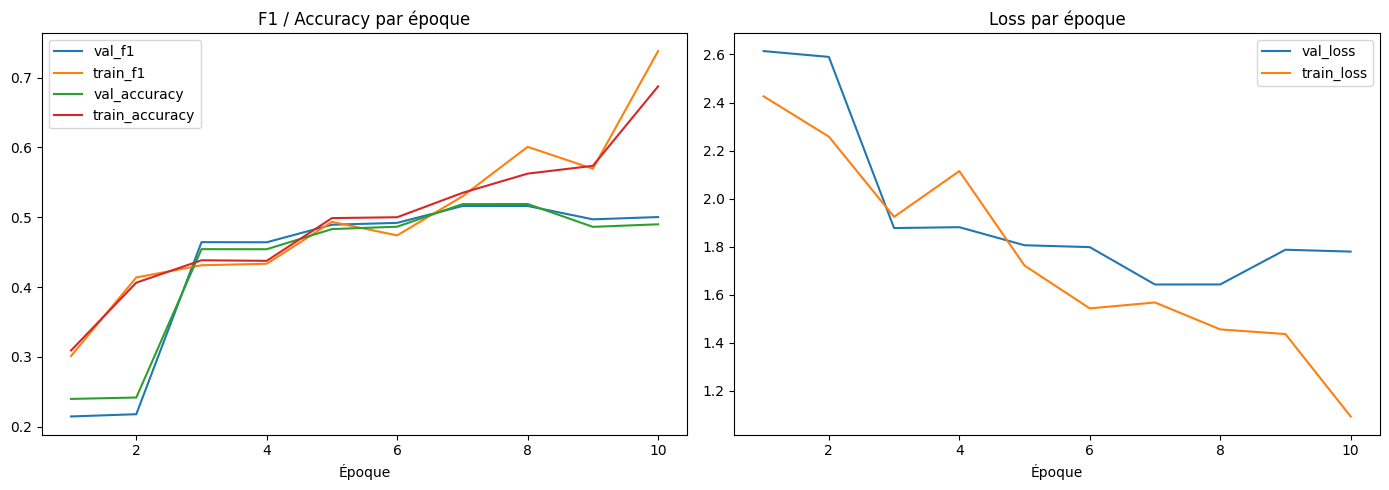

              precision    recall  f1-score   support

          10       0.39      0.51      0.44       311
        1140       0.56      0.44      0.49       267
        1160       0.83      0.85      0.84       396
        1180       0.33      0.25      0.28        76
        1280       0.42      0.21      0.28       487
        1281       0.22      0.34      0.27       207
        1300       0.57      0.62      0.60       505
        1301       0.49      0.54      0.51        81
        1302       0.33      0.22      0.26       249
        1320       0.38      0.37      0.38       324
        1560       0.65      0.31      0.42       507
        1920       0.75      0.74      0.74       431
        1940       0.46      0.73      0.56        81
        2060       0.42      0.48      0.45       499
        2220       0.17      0.33      0.23        82
        2280       0.70      0.71      0.70       476
        2403       0.84      0.41      0.55       477
        2462       0.61    

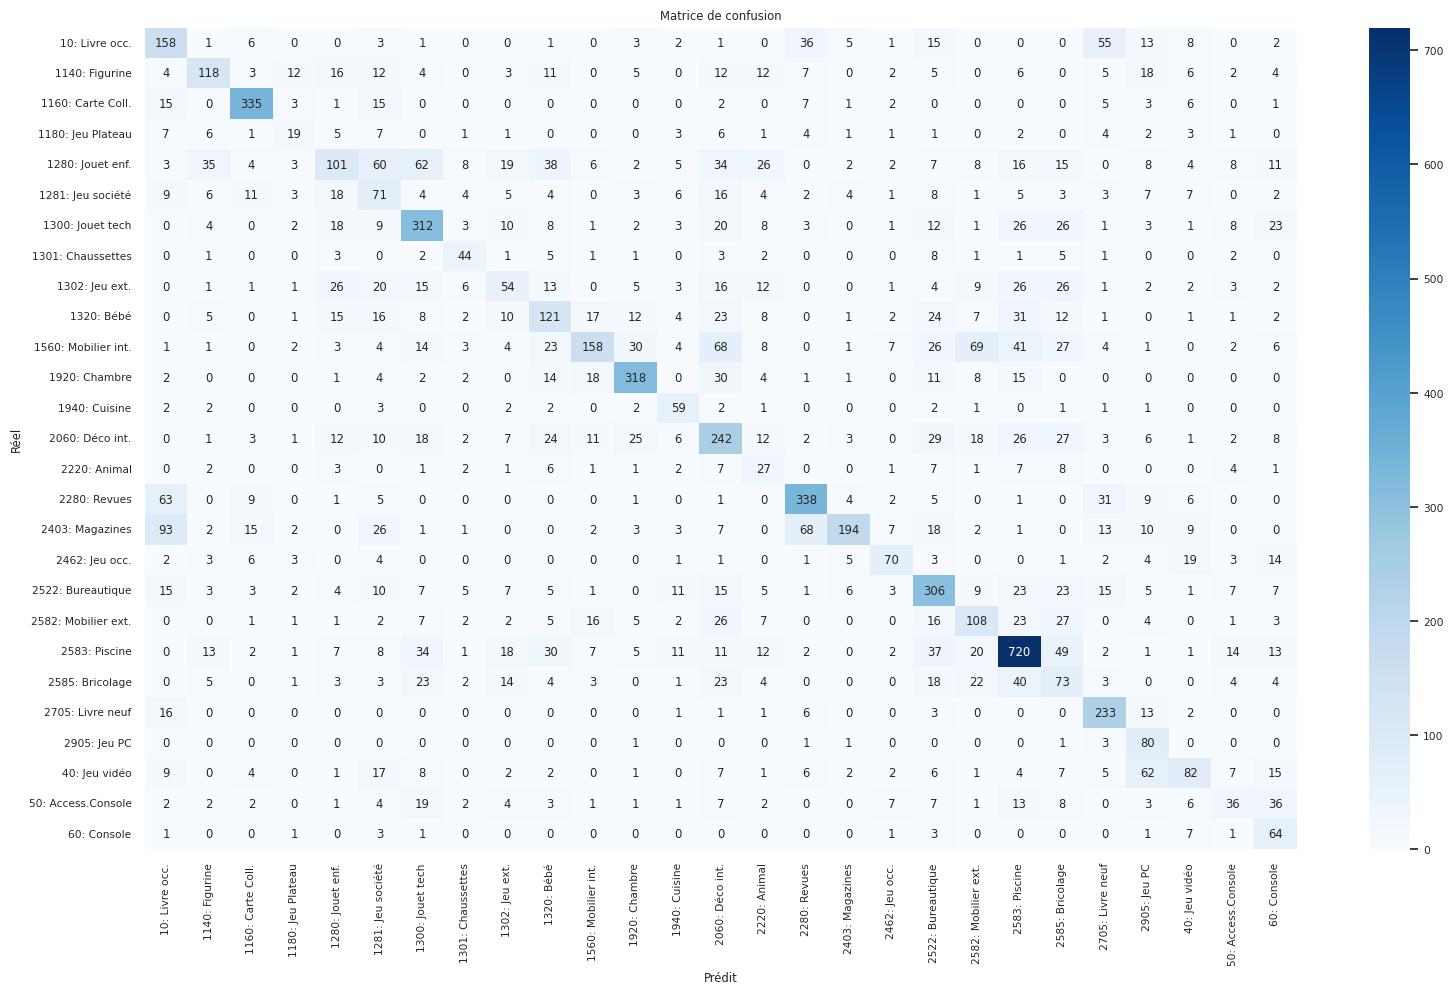

model_name                                       ResNet50 — 20% data — lr=0.0001
dataset_resampled                                                           True
image_dataset_zoomed                                                        True
train_size                                                               21913.0
image_size                                                                 224.0
image_color_rgb                                                             True
batch_size                                                                  32.0
image_data_generator_params    {'rescale': 0.00392156862745098, 'preprocessin...
start_lr                                                                  0.0001
last_lr                                                                   0.0001
optimizer                                                                   adam
target_epochs                                                               10.0
last_epoch                  

In [11]:
if training_history is not None:
    model = load_saved_model(model_id)

test_pred       = model.predict(test_gen, verbose=1)
test_pred_class = [classes_keras[c] for c in np.argmax(test_pred, axis=1)]
y_test_str      = df_test['prdtypecode'].astype("str").values

f1  = f1_score(y_test_str, test_pred_class, average="weighted")
acc = accuracy_score(y_test_str, test_pred_class)
update_reporting_line(model_id, {"test_f1_score": f1, "test_accuracy": acc})

print(f"F1 Test  : {f1:.4f}")
print(f"Accuracy : {acc:.4f}")

history = get_full_history(model_id, training_history)
if history:
    save_history(model_id, history)
    training_history = None
    plot_training_history(history)

print(classification_report(y_test_str, test_pred_class))
cm = pd.crosstab(y_test_str, test_pred_class)
plot_confusion_matrix(np.array(cm), classes_keras)
display(reporting_df.loc[model_id].T)

# CELLULE 11 — Modélisation 2.1.2 : ResNet152 frozen + 20 dernières couches, LR=0.0001

Found 21913 validated image filenames belonging to 27 classes.
Found 8492 validated image filenames belonging to 27 classes.
Found 8492 validated image filenames belonging to 27 classes.
   Aucun modèle trouvé pour 212
234698864/234698864 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Paramètres entraînables : 61,007,771


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
684/684 ━━━━━━━━━━━━━━━━━━━━ 0s 525ms/step - accuracy: 0.0708 - loss: 3.2539 - w_f1_score: 0.2823
   ✅ Meilleur modèle — val_f1=0.0954
   💾 Modèle 212 sauvegardé → /kaggle/working/modeling-resnet/model-212.keras
684/684 ━━━━━━━━━━━━━━━━━━━━ 463s 631ms/step - accuracy: 0.0709 - loss: 3.2537 - w_f1_score: 0.2822 - val_accuracy: 0.1176 - val_loss: 2.9862 - val_w_f1_score: 0.0954
Epoch 2/10
  1/684 ━━━━━━━━━━━━━━━━━━━━ 3:30 308ms/step - accuracy: 0.0625 - loss: 3.1235 - w_f1_score: 0.0875

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



   ✅ Meilleur modèle — val_f1=0.1025
   💾 Modèle 212 sauvegardé → /kaggle/working/modeling-resnet/model-212.keras
684/684 ━━━━━━━━━━━━━━━━━━━━ 62s 91ms/step - accuracy: 0.0625 - loss: 3.1235 - w_f1_score: 0.0875 - val_accuracy: 0.1226 - val_loss: 2.9714 - val_w_f1_score: 0.1025
Epoch 3/10
684/684 ━━━━━━━━━━━━━━━━━━━━ 0s 502ms/step - accuracy: 0.1274 - loss: 2.9983 - w_f1_score: 0.1156
   ✅ Meilleur modèle — val_f1=0.1234
   💾 Modèle 212 sauvegardé → /kaggle/working/modeling-resnet/model-212.keras
684/684 ━━━━━━━━━━━━━━━━━━━━ 406s 593ms/step - accuracy: 0.1274 - loss: 2.9983 - w_f1_score: 0.1156 - val_accuracy: 0.1560 - val_loss: 2.8900 - val_w_f1_score: 0.1234
Epoch 4/10
  1/684 ━━━━━━━━━━━━━━━━━━━━ 3:14 285ms/step - accuracy: 0.0938 - loss: 3.1618 - w_f1_score: 0.1031
   ✅ Meilleur modèle — val_f1=0.1252
   💾 Modèle 212 sauvegardé → /kaggle/working/modeling-resnet/model-212.keras
684/684 ━━━━━━━━━━━━━━━━━━━━ 62s 91ms/step - accuracy: 0.0938 - loss: 3.1618 - w_f1_score: 0.1031 - val_a

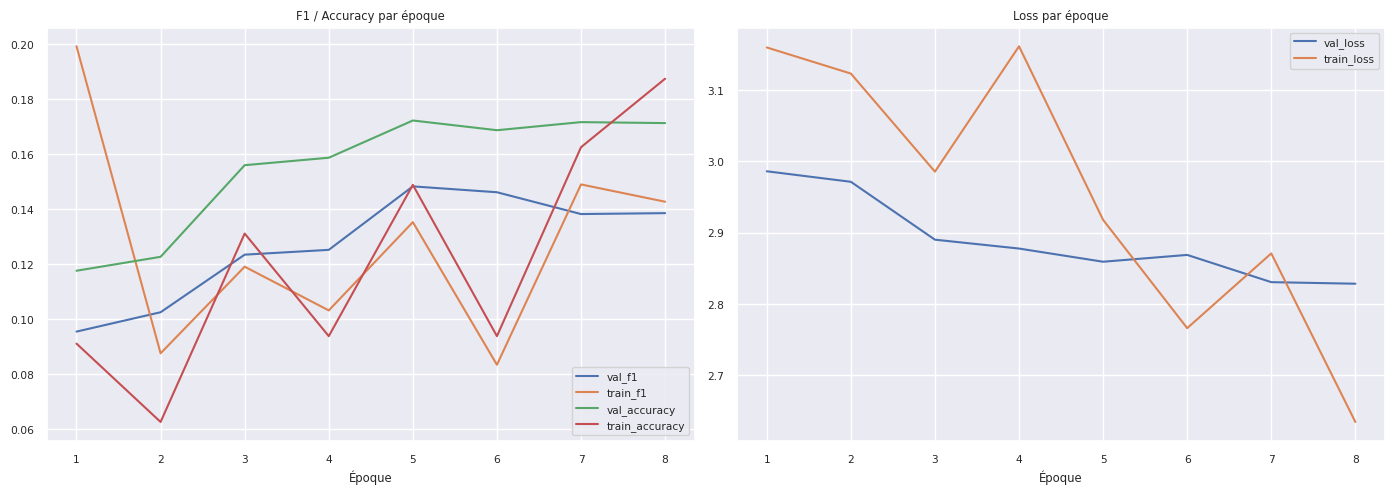

              precision    recall  f1-score   support

          10       0.18      0.22      0.20       311
        1140       0.16      0.19      0.17       267
        1160       0.46      0.26      0.33       396
        1180       0.07      0.01      0.02        76
        1280       0.28      0.02      0.04       487
        1281       0.05      0.03      0.04       207
        1300       0.23      0.42      0.30       505
        1301       0.05      0.14      0.07        81
        1302       0.06      0.03      0.04       249
        1320       0.14      0.00      0.01       324
        1560       0.23      0.06      0.09       507
        1920       0.34      0.38      0.36       431
        1940       0.01      0.01      0.01        81
        2060       0.29      0.03      0.06       499
        2220       0.00      0.00      0.00        82
        2280       0.25      0.18      0.21       476
        2403       0.32      0.25      0.28       477
        2462       0.11    

In [12]:
model_id      = 212
target_epochs = 10

add_reporting_line(model_id, "ResNet152 — 20 dernières couches — lr=0.0001")

def build_resnet152_partial():
    """ResNet152 avec freeze partiel — seules les 20 dernières couches entraînées."""
    base = tf.keras.applications.ResNet152(
        weights='imagenet', include_top=False, input_shape=(224, 224, 3))

    for layer in base.layers:
        layer.trainable = False
    for layer in base.layers[-20:]:
        layer.trainable = True

    x   = GlobalAveragePooling2D()(base.output)
    x   = Dense(1024, activation='relu')(x)
    x   = Dropout(0.4)(x)
    x   = Dense(512, activation='relu')(x)
    x   = Dropout(0.4)(x)
    out = Dense(NUM_CLASSES, activation='softmax')(x)

    return Model(inputs=base.input, outputs=out)

# On réutilise le même sous-ensemble que modélisation précédente
train_gen, val_gen, test_gen = make_generators(
    pd.concat([X_sub, y_sub], axis=1),
    pd.concat([X_val, y_val],  axis=1),
    pd.concat([X_test, y_test], axis=1)
)

update_reporting_line(model_id, {
    "dataset_resampled": True, "image_dataset_zoomed": True,
    "train_size": len(X_sub), "image_size": target_img_size[0],
    "image_color_rgb": True, "batch_size": batch_size,
    "start_lr": start_lr, "optimizer": "adam",
    "target_epochs": target_epochs,
    "remarks": "ResNet152 — freeze partiel, 20 dernières couches actives"
})

model = load_saved_model(model_id)
if model is None:
    model = build_resnet152_partial()
    model.compile(
        optimizer=Adam(learning_rate=start_lr),
        loss='categorical_crossentropy',
        metrics=['accuracy', w_f1_score]
    )
    trainable = sum(p for layer in model.layers for p in [layer.count_params() if layer.trainable else 0])
    print(f"Paramètres entraînables : {model.count_params():,}")

if not get_reporting_value(model_id, "fit_complete", False):
    training_history = model.fit(
        train_gen,
        validation_data=val_gen,
        steps_per_epoch=train_gen.samples // batch_size,
        validation_steps=val_gen.samples // batch_size,
        epochs=target_epochs - int(get_reporting_value(model_id, "last_epoch", 0)),
        verbose=1,
        callbacks=[LogBest(model_id), early_stopping]
    )
    update_reporting_line(model_id, {"fit_complete": True})
else:
    print("Déjà entraîné")
    training_history = None

# Évaluation
if training_history is not None:
    model = load_saved_model(model_id)

test_pred       = model.predict(test_gen, verbose=1)
test_pred_class = [classes_keras[c] for c in np.argmax(test_pred, axis=1)]

f1  = f1_score(y_test_str, test_pred_class, average="weighted")
acc = accuracy_score(y_test_str, test_pred_class)
update_reporting_line(model_id, {"test_f1_score": f1, "test_accuracy": acc})
print(f"F1 Test  : {f1:.4f} | Accuracy : {acc:.4f}")

history = get_full_history(model_id, training_history)
if history:
    save_history(model_id, history); training_history = None
    plot_training_history(history)
print(classification_report(y_test_str, test_pred_class))

# CELLULE 12 — Modélisation 2.1.3 : ResNet152, 45 couches, BatchNorm, dataset 80%

Sous-ensemble train : 87,652 produits
Found 87652 validated image filenames belonging to 27 classes.
Found 8492 validated image filenames belonging to 27 classes.
Found 8492 validated image filenames belonging to 27 classes.
   Aucun modèle trouvé pour 213


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
2739/2739 ━━━━━━━━━━━━━━━━━━━━ 0s 578ms/step - accuracy: 0.0927 - loss: 3.5789 - w_f1_score: 0.1054
   ✅ Meilleur modèle — val_f1=0.1582
   💾 Modèle 213 sauvegardé → /kaggle/working/modeling-resnet/model-213.keras
2739/2739 ━━━━━━━━━━━━━━━━━━━━ 1696s 605ms/step - accuracy: 0.0927 - loss: 3.5788 - w_f1_score: 0.1055 - val_accuracy: 0.1783 - val_loss: 2.9513 - val_w_f1_score: 0.1582
Epoch 2/10
   1/2739 ━━━━━━━━━━━━━━━━━━━━ 15:41 344ms/step - accuracy: 0.1250 - loss: 3.0667 - w_f1_score: 0.1052

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


2739/2739 ━━━━━━━━━━━━━━━━━━━━ 60s 22ms/step - accuracy: 0.1250 - loss: 3.0667 - w_f1_score: 0.1052 - val_accuracy: 0.1745 - val_loss: 2.9564 - val_w_f1_score: 0.1537
Epoch 3/10
2739/2739 ━━━━━━━━━━━━━━━━━━━━ 0s 497ms/step - accuracy: 0.1442 - loss: 3.0903 - w_f1_score: 0.1362
   ✅ Meilleur modèle — val_f1=0.1710
   💾 Modèle 213 sauvegardé → /kaggle/working/modeling-resnet/model-213.keras
2739/2739 ━━━━━━━━━━━━━━━━━━━━ 1425s 520ms/step - accuracy: 0.1442 - loss: 3.0903 - w_f1_score: 0.1362 - val_accuracy: 0.1907 - val_loss: 2.9008 - val_w_f1_score: 0.1710
Epoch 4/10
2739/2739 ━━━━━━━━━━━━━━━━━━━━ 60s 22ms/step - accuracy: 0.1562 - loss: 3.1526 - w_f1_score: 0.1521 - val_accuracy: 0.1897 - val_loss: 2.9103 - val_w_f1_score: 0.1707
Epoch 5/10
2739/2739 ━━━━━━━━━━━━━━━━━━━━ 0s 501ms/step - accuracy: 0.1741 - loss: 2.9292 - w_f1_score: 0.1649
   ✅ Meilleur modèle — val_f1=0.1729
   💾 Modèle 213 sauvegardé → /kaggle/working/modeling-resnet/model-213.keras
2739/2739 ━━━━━━━━━━━━━━━━━━━━ 1436

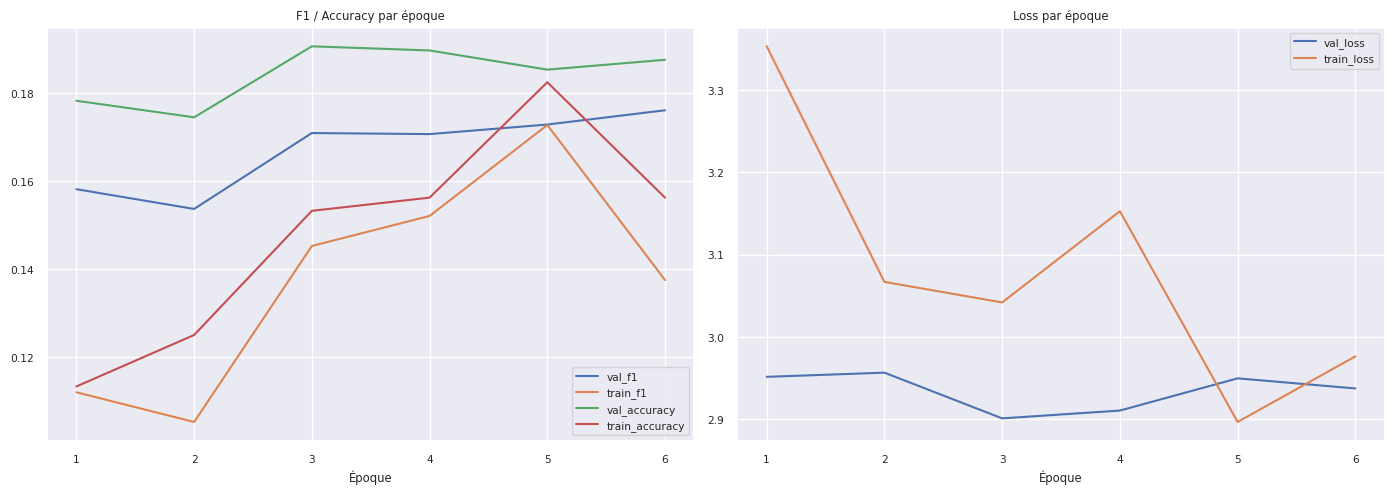

              precision    recall  f1-score   support

          10       0.34      0.14      0.20       311
        1140       0.26      0.24      0.25       267
        1160       0.39      0.65      0.49       396
        1180       0.04      0.04      0.04        76
        1280       0.21      0.01      0.03       487
        1281       0.09      0.04      0.05       207
        1300       0.33      0.13      0.19       505
        1301       0.04      0.15      0.07        81
        1302       0.12      0.03      0.05       249
        1320       0.15      0.08      0.10       324
        1560       0.28      0.04      0.07       507
        1920       0.14      0.69      0.24       431
        1940       0.06      0.43      0.10        81
        2060       0.16      0.14      0.15       499
        2220       0.04      0.23      0.06        82
        2280       0.46      0.17      0.25       476
        2403       0.37      0.20      0.26       477
        2462       0.21    

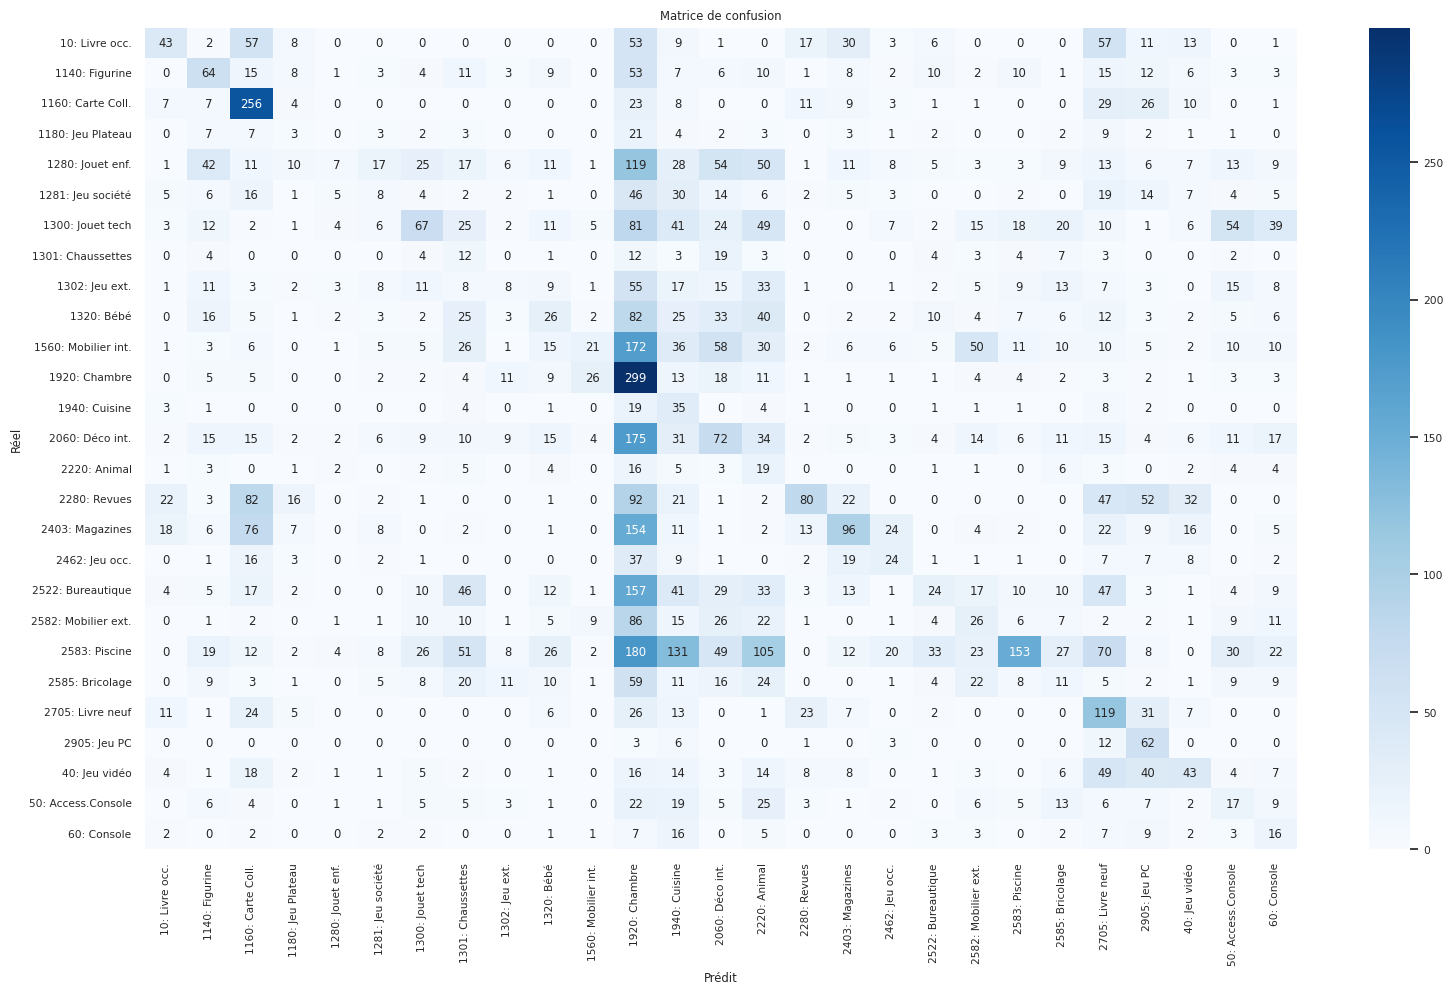

model_name                         ResNet152 — 45 couches — BatchNorm — 80% data
dataset_resampled                                                           True
image_dataset_zoomed                                                        True
train_size                                                               87652.0
image_size                                                                 224.0
image_color_rgb                                                             True
batch_size                                                                  32.0
image_data_generator_params                                                  NaN
start_lr                                                                  0.0001
last_lr                                                                   0.0001
optimizer                                                                   adam
target_epochs                                                               10.0
last_epoch                  

In [13]:
model_id      = 213
target_epochs = 10
subset_ratio  = 0.80

add_reporting_line(model_id, "ResNet152 — 45 couches — BatchNorm — 80% data")

def build_resnet152_deep():
    """ResNet152 avec 45 dernières couches entraînées + BatchNorm dans le classifier."""
    base = tf.keras.applications.ResNet152(
        weights='imagenet', include_top=False, input_shape=(224, 224, 3))

    for layer in base.layers:
        layer.trainable = False
    for layer in base.layers[-45:]:
        layer.trainable = True

    x   = GlobalAveragePooling2D()(base.output)
    x   = Dense(1024, activation='relu')(x)
    x   = BatchNormalization()(x)
    x   = Dropout(0.3)(x)
    x   = Dense(512, activation='relu')(x)
    x   = BatchNormalization()(x)
    x   = Dropout(0.3)(x)
    out = Dense(NUM_CLASSES, activation='softmax')(x)

    return Model(inputs=base.input, outputs=out)

# Sous-ensemble 80%
target_size = int(len(X_train) * subset_ratio)
split_rate  = (len(X_train) - target_size) / len(X_train)
X_sub80, _, y_sub80, _ = train_test_split(
    X_train, y_train,
    test_size=split_rate,
    random_state=random_state,
    stratify=y_train
)
print(f"Sous-ensemble train : {len(X_sub80):,} produits")

train_gen, val_gen, test_gen = make_generators(
    pd.concat([X_sub80, y_sub80], axis=1),
    pd.concat([X_val, y_val],     axis=1),
    pd.concat([X_test, y_test],   axis=1)
)

update_reporting_line(model_id, {
    "dataset_resampled": True, "image_dataset_zoomed": True,
    "train_size": len(X_sub80), "image_size": target_img_size[0],
    "image_color_rgb": True, "batch_size": batch_size,
    "start_lr": start_lr, "optimizer": "adam",
    "target_epochs": target_epochs,
    "remarks": "ResNet152 — 45 couches actives — BatchNorm — 80% data"
})

model = load_saved_model(model_id)
if model is None:
    model = build_resnet152_deep()
    model.compile(
        optimizer=Adam(learning_rate=start_lr),
        loss='categorical_crossentropy',
        metrics=['accuracy', w_f1_score]
    )

if not get_reporting_value(model_id, "fit_complete", False):
    training_history = model.fit(
        train_gen,
        validation_data=val_gen,
        steps_per_epoch=train_gen.samples // batch_size,
        validation_steps=val_gen.samples // batch_size,
        epochs=target_epochs - int(get_reporting_value(model_id, "last_epoch", 0)),
        verbose=1,
        callbacks=[LogBest(model_id), early_stopping]
    )
    update_reporting_line(model_id, {"fit_complete": True})
else:
    print("Déjà entraîné")
    training_history = None

# Évaluation
if training_history is not None:
    model = load_saved_model(model_id)

test_pred       = model.predict(test_gen, verbose=1)
test_pred_class = [classes_keras[c] for c in np.argmax(test_pred, axis=1)]

f1  = f1_score(y_test_str, test_pred_class, average="weighted")
acc = accuracy_score(y_test_str, test_pred_class)
update_reporting_line(model_id, {"test_f1_score": f1, "test_accuracy": acc})
print(f"F1 Test  : {f1:.4f} | Accuracy : {acc:.4f}")

history = get_full_history(model_id, training_history)
if history:
    save_history(model_id, history); training_history = None
    plot_training_history(history)
print(classification_report(y_test_str, test_pred_class))
cm = pd.crosstab(y_test_str, test_pred_class)
plot_confusion_matrix(np.array(cm), classes_keras)
display(reporting_df.loc[model_id].T)

# CELLULE 13 — Comparaison finale

model_id,211,212,213
model_name,ResNet50 — 20% data — lr=0.0001,ResNet152 — 20 dernières couches — lr=0.0001,ResNet152 — 45 couches — BatchNorm — 80% data
train_size,21913.0,21913.0,87652.0
test_f1_score,0.519687,0.145891,0.17573
test_accuracy,0.522963,0.168629,0.189708
val_f1_score,0.516121,0.148296,0.176129
last_epoch,10.0,8.0,6.0
remarks,NaN,"ResNet152 — freeze partiel, 20 dernières couch...",ResNet152 — 45 couches actives — BatchNorm — 8...


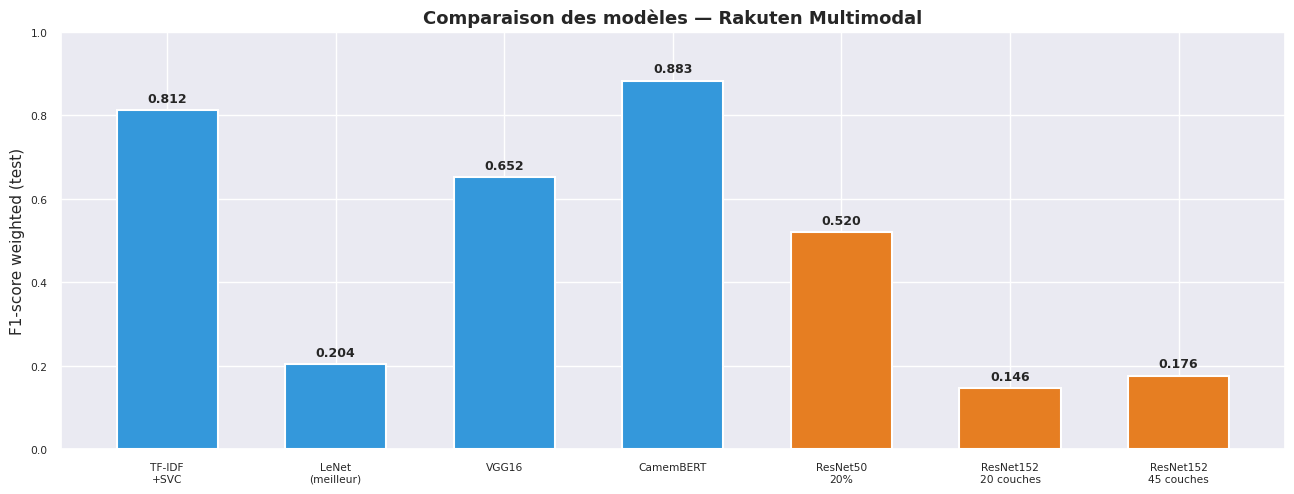


📊 Résumé ResNet :
   ResNet50 — 20% data — lr=0.0001          F1 Test = 0.5197
   ResNet152 — 20 dernières couches — lr=0.0001 F1 Test = 0.1459
   ResNet152 — 45 couches — BatchNorm — 80% data F1 Test = 0.1757

   VGG16 (référence)                        F1 Test = 0.6521
   CamemBERT (référence)                    F1 Val  = 0.8826


In [14]:
cols = ["model_name", "train_size", "test_f1_score", "test_accuracy",
        "val_f1_score", "last_epoch", "remarks"]
reporting_df = load_reporting_df()

ids_resnet = [i for i in [211, 212, 213] if i in reporting_df.index]
if ids_resnet:
    display(reporting_df.loc[ids_resnet, cols].T)

# Barplot comparaison globale
comparaison = {
    'TF-IDF\n+SVC'      : 0.8121,
    'LeNet\n(meilleur)' : 0.2039,
    'VGG16'             : 0.6521,
    'CamemBERT'         : 0.8826,
}
for mid, nom in [(211, 'ResNet50\n20%'), (212, 'ResNet152\n20 couches'), (213, 'ResNet152\n45 couches')]:
    if mid in reporting_df.index:
        comparaison[nom] = reporting_df.at[mid, 'test_f1_score']

fig, ax = plt.subplots(figsize=(13, 5))
colors = ['#3498db'] * 4 + ['#e67e22'] * len(ids_resnet)
bars   = ax.bar(comparaison.keys(), comparaison.values(),
                color=colors, edgecolor='white', linewidth=1.5, width=0.6)
ax.set_ylim(0, 1.0)
ax.set_ylabel("F1-score weighted (test)", fontsize=11)
ax.set_title("Comparaison des modèles — Rakuten Multimodal", fontsize=13, fontweight='bold')
for bar, val in zip(bars, comparaison.values()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
            f'{val:.3f}', ha='center', fontweight='bold', fontsize=9)
plt.tight_layout()
plt.savefig(WORK_DIR / 'resnet_comparaison.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n📊 Résumé ResNet :")
for mid in ids_resnet:
    nom = reporting_df.at[mid, 'model_name']
    f1  = reporting_df.at[mid, 'test_f1_score']
    print(f"   {nom:<40} F1 Test = {f1:.4f}")
print(f"\n   VGG16 (référence)                        F1 Test = 0.6521")
print(f"   CamemBERT (référence)                    F1 Val  = 0.8826")